Latihan: Data Loading

In [6]:
import pandas as pd

# Memuat dataset train dan test
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

# Menampilkan 5 baris pertama dari data train untuk memastikan data berhasil dimuat
train.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Target
0,3.1908,52.0,5.000000,1.014184,879.0,3.117021,37.71,-122.43,2.556
1,3.6094,42.0,4.900990,0.957096,971.0,3.204620,37.95,-122.35,1.146
2,2.6250,16.0,8.333333,1.666667,20.0,3.333333,37.90,-121.24,1.375
3,1.5143,34.0,3.805981,1.149526,3538.0,2.580598,34.02,-118.35,1.188
4,7.3356,38.0,5.894904,1.057325,750.0,2.388535,33.89,-118.39,4.227


In [7]:
import pandas as pd

# Memuat dataset train dan test
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

# Menampilkan 5 baris pertama dari data train untuk memastikan data berhasil dimuat
test.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Target
0,3.2500,39.0,4.503205,1.073718,1109.0,1.777244,34.06,-118.36,3.550
1,1.9784,37.0,4.988584,1.038813,1143.0,2.609589,36.78,-119.78,0.707
2,4.0132,46.0,4.480296,1.012315,1534.0,3.778325,37.73,-122.42,2.294
3,1.5208,52.0,3.908046,1.114943,200.0,2.298851,37.81,-122.28,1.125
4,5.1795,37.0,5.406360,1.024735,711.0,2.512367,33.82,-118.13,2.254


Latihan: Data Cleaning dan Transformation

In [8]:
import pandas as pd
train = pd.read_csv('train.csv')

Mengidentifikasi Informasi Dataset

In [9]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 16512 entries, 0 to 16511
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      16512 non-null  float64
 1   HouseAge    16512 non-null  float64
 2   AveRooms    16512 non-null  float64
 3   AveBedrms   16512 non-null  float64
 4   Population  16512 non-null  float64
 5   AveOccup    16512 non-null  float64
 6   Latitude    16512 non-null  float64
 7   Longitude   16512 non-null  float64
 8   Target      16512 non-null  float64
dtypes: float64(9)
memory usage: 1.1 MB


In [10]:
train.describe(include="all")

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Target
count,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000
mean,3.876149,28.604469,5.441114,1.099598,1425.257146,3.094971,35.632194,-119.574288,2.077351
std,1.891584,12.586046,2.613727,0.507173,1123.756792,11.597402,2.137087,2.007578,1.155945
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.750000,32.540000,-124.300000,0.149990
25%,2.572050,18.000000,4.439906,1.006260,786.000000,2.427283,33.930000,-121.810000,1.206000
50%,3.544550,29.000000,5.226528,1.048797,1164.000000,2.813449,34.260000,-118.490000,1.806000
75%,4.750000,37.000000,6.057778,1.099574,1723.000000,3.273834,37.710000,-118.010000,2.660000
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [11]:
missing_values = train.isnull().sum()
missing_values[missing_values > 0]

Series([], dtype: int64)

Mengatasi Missing Value

In [12]:
less = missing_values[missing_values < 1000].index
over = missing_values[missing_values >= 1000].index

In [13]:
numeric_features = train[less].select_dtypes(include=['number']).columns
train[numeric_features] = train[numeric_features].fillna(train[numeric_features].median())

In [14]:
katagorical_features = train[less].select_dtypes(include=['object']).columns
for col in katagorical_features:
    train[col] = train[col].fillna(train[col].mode()[0])

In [15]:
df = train.drop(columns=over)

In [16]:
missing_values = df.isnull().sum()
missing_values[missing_values > 0]

Series([], dtype: int64)

Mengatasi Outliers

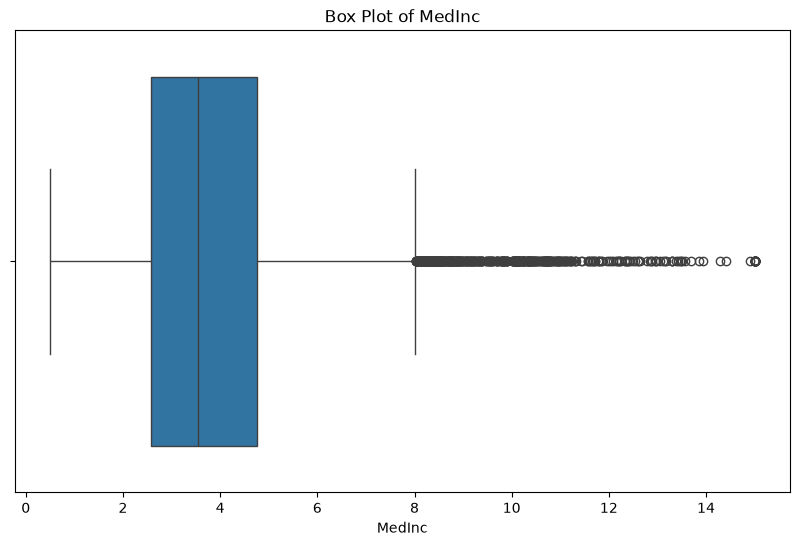

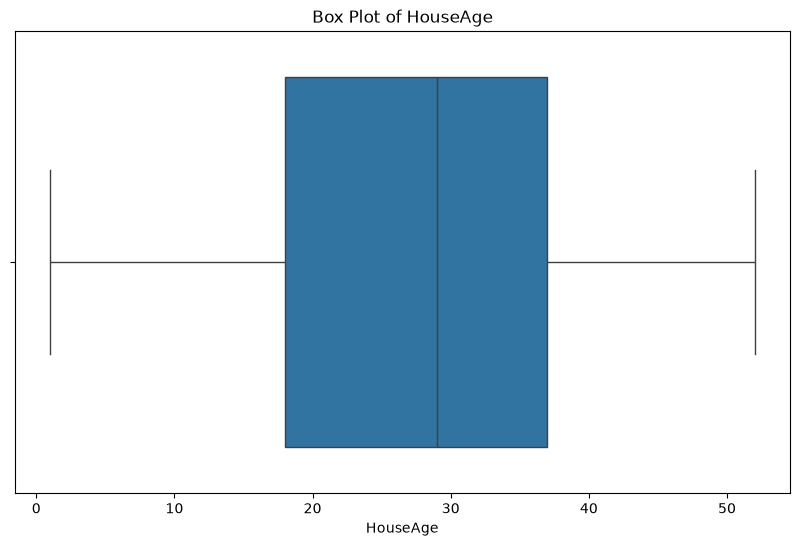

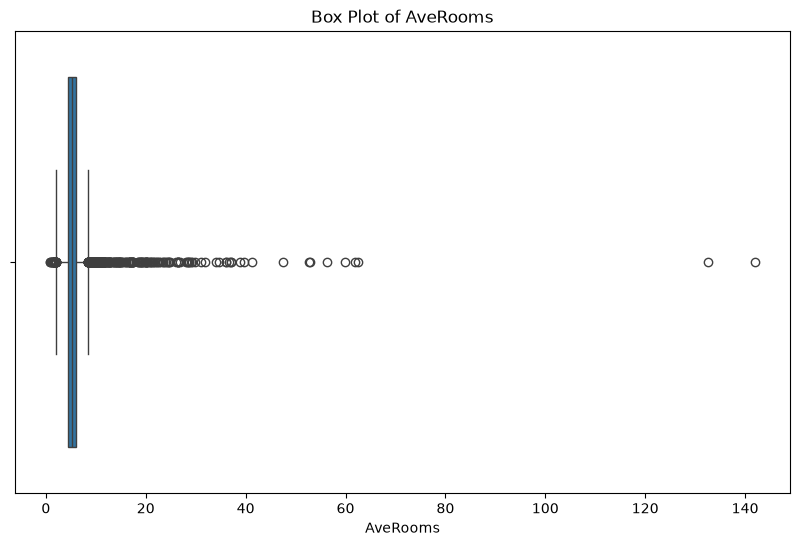

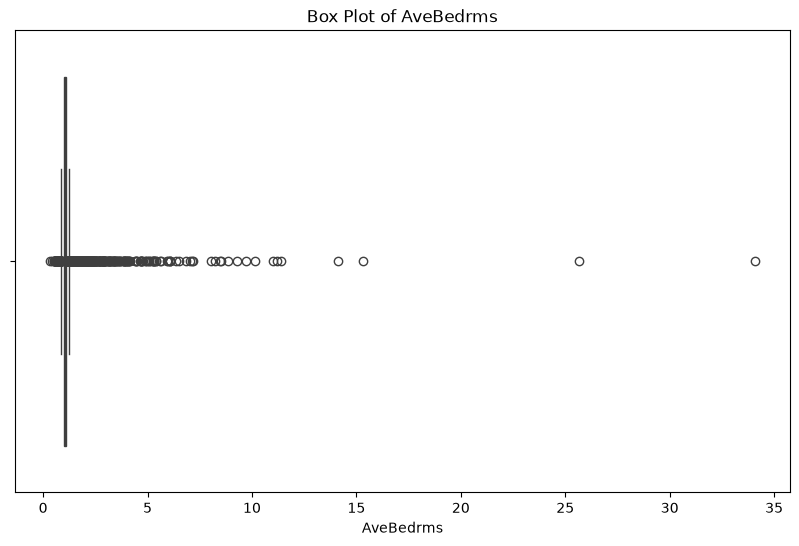

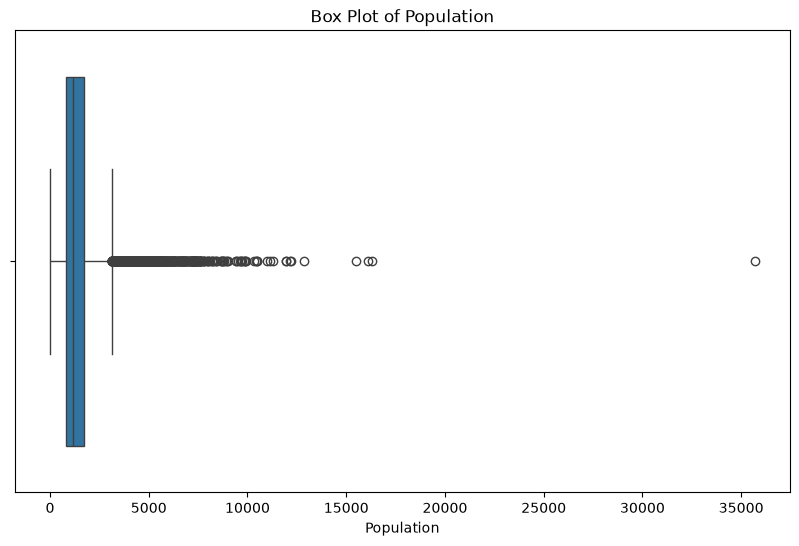

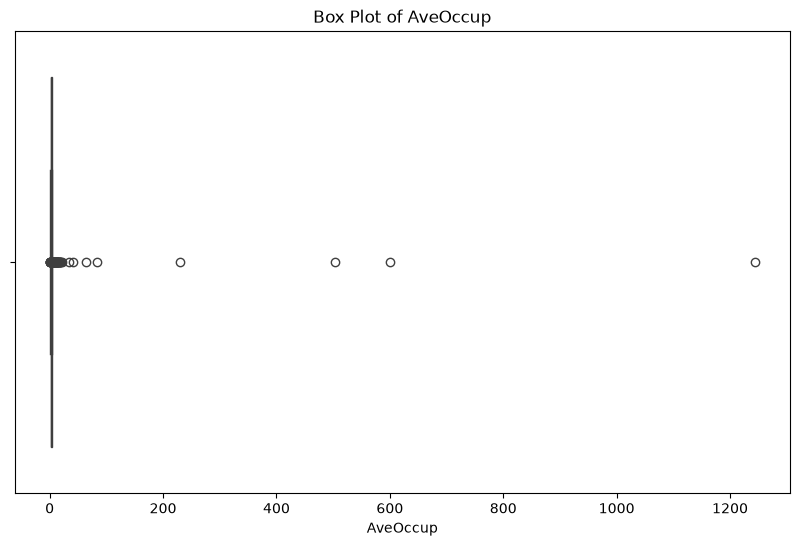

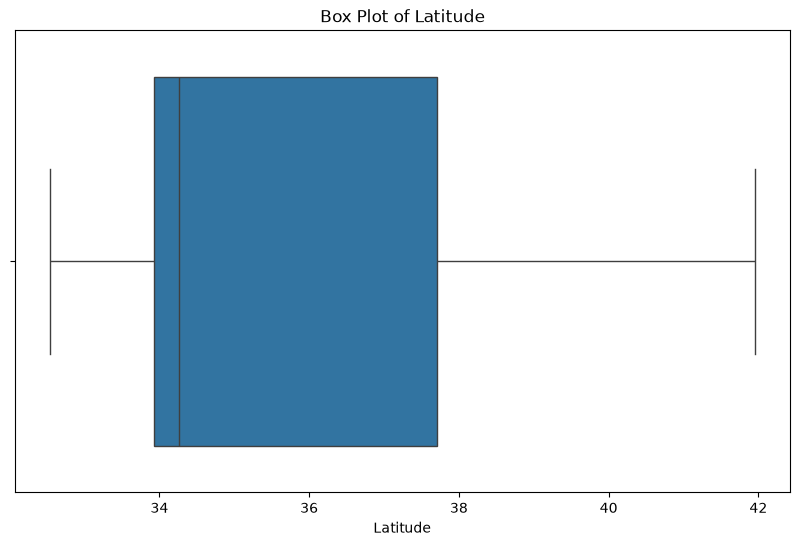

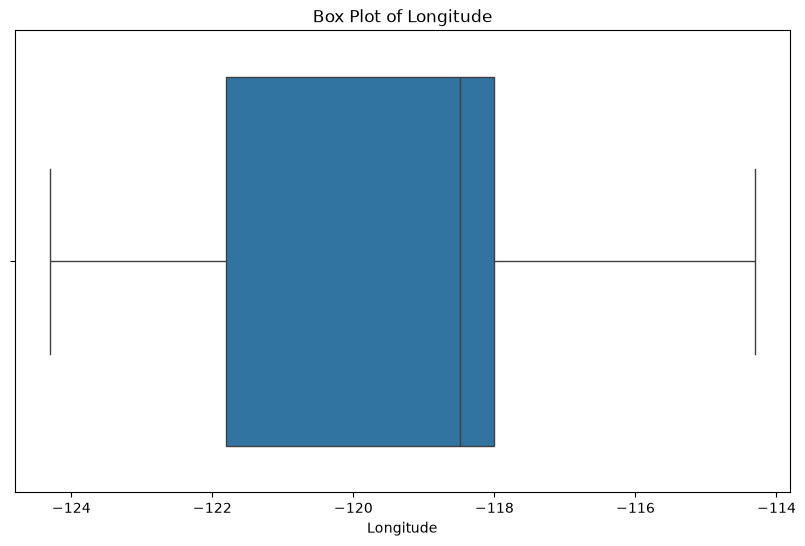

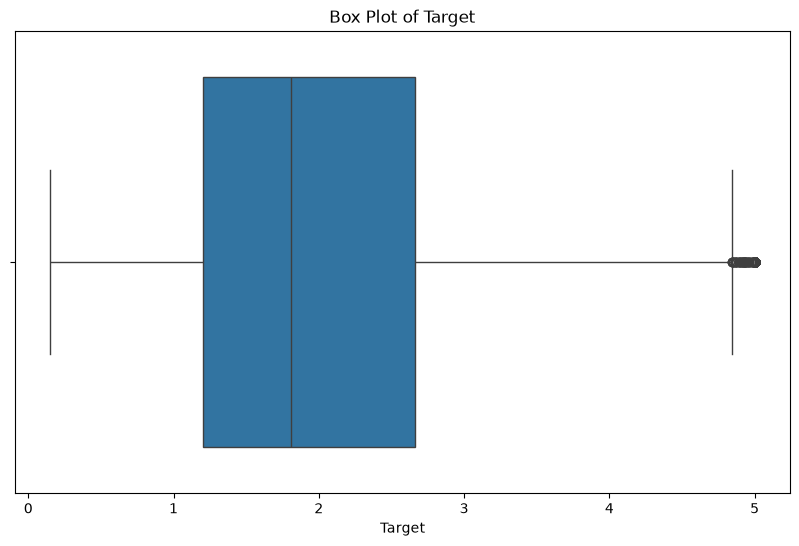

In [17]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

for feature in numeric_features:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=df[feature])
    plt.title(f'Box Plot of {feature}')
    plt.show()

In [18]:
Q1 = df[numeric_features].quantile(0.25)
Q3 = df[numeric_features].quantile(0.75)
IQR = Q3 - Q1

In [19]:
# Pastikan ulang kolom numerik terambil dari dataframe df yang aktif
numeric_features = df.select_dtypes(include=['number']).columns

# Hitung kembali Q1, Q3, dan IQR
Q1 = df[numeric_features].quantile(0.25)
Q3 = df[numeric_features].quantile(0.75)
IQR = Q3 - Q1

# Filter dataframe untuk menyaring outliers
condition = ~((df[numeric_features] < (Q1 - 1.5 * IQR)) | (df[numeric_features] > (Q3 + 1.5 * IQR)))
df_filtered_numeric = df.loc[condition.all(axis=1), numeric_features]

# Menggabungkan kembali dengan kolom kategorikal
categorical_features = df.select_dtypes(include=['object']).columns
df = pd.concat([df_filtered_numeric, df.loc[condition.all(axis=1), categorical_features]], axis=1)

Normalisasi dan Standardisasi Data

In [20]:
from sklearn.preprocessing import StandardScaler

# Standardisasi fitur numerik
scaler = StandardScaler()
df[numeric_features] = scaler.fit_transform(df[numeric_features])

Text(0.5, 1.0, 'Histogram Sebelum Standardisasi')

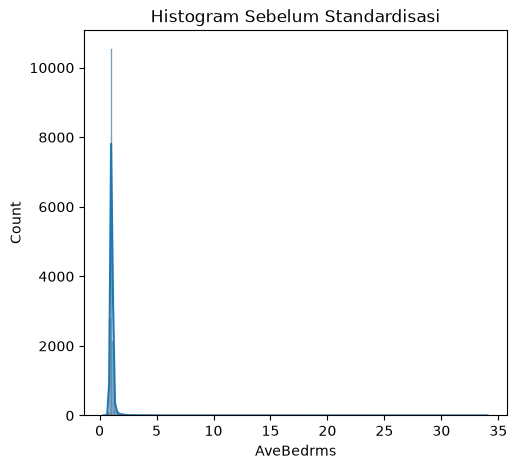

In [21]:
# Histogram Sebelum Standardisasi
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(train[numeric_features[3]], kde=True)
plt.title("Histogram Sebelum Standardisasi")

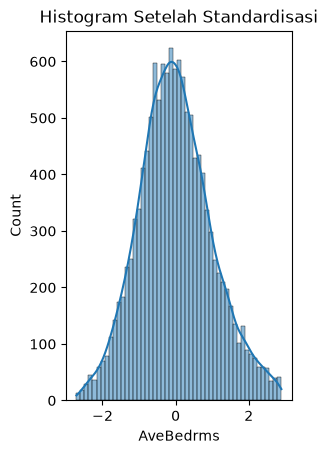

In [22]:
# Histogram Setelah Standardisasi
plt.subplot(1, 2, 2)
sns.histplot(df[numeric_features[3]], kde=True)
plt.title("Histogram Setelah Standardisasi")
plt.show()

Menangani Duplikasi Data

In [23]:
# Mengidentifikasi baris duplikat
duplicates = df.duplicated()
print("Baris duplikat:")
print(df[duplicates])

Baris duplikat:
Empty DataFrame
Columns: [MedInc, HouseAge, AveRooms, AveBedrms, Population, AveOccup, Latitude, Longitude, Target]
Index: []


In [24]:
# Menghapus baris duplikat
df = df.drop_duplicates()
print("DataFrame setelah menghapus duplikasi:")
print(df)

DataFrame setelah menghapus duplikasi:
         MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  \
0     -0.328642  1.847078 -0.147976  -0.495571   -0.623878  0.415633   
1     -0.039420  1.028700 -0.242404  -1.353805   -0.476555  0.556513   
4      2.535108  0.701349  0.705521   0.152974   -0.830449 -0.755946   
5     -1.721963 -0.362542 -1.589893  -0.391483   -0.759991 -1.228041   
6      1.369447 -0.280704  2.360129  -0.133065   -0.985778 -0.128430   
...         ...       ...       ...        ...         ...       ...   
16506  0.568733  0.455836  0.367444   0.090836    0.314502  0.415633   
16507 -1.301811 -1.017244 -1.049206   0.601436   -0.303612 -0.617259   
16509 -1.750705  1.028700 -0.252137  -0.606193   -0.790416 -0.343407   
16510 -0.714593 -1.590109 -0.155973  -1.433688    0.087113 -0.136694   
16511 -0.941631  0.455836 -0.509904   1.950936   -0.415705 -0.436479   

       Latitude  Longitude    Target  
0      0.953650  -1.398573  0.653653  
1      1.065907  -

Mengonversi Tipe Data

In [25]:
# Menampilkan kolom kategorikal pada dataset
category_features = df.select_dtypes(include=['object']).columns
df[category_features]

""
0
1
4
5
6
...
16506
16507
16509
16510


In [26]:
# Mengubah kolom kategorikal menjadi format biner (one-hot encoding)
df_one_hot = pd.get_dummies(df, columns=category_features)
df_one_hot

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Target
0,-0.328642,1.847078,-0.147976,-0.495571,-0.623878,0.415633,0.953650,-1.398573,0.653653
1,-0.039420,1.028700,-0.242404,-1.353805,-0.476555,0.556513,1.065907,-1.358549,-0.835207
4,2.535108,0.701349,0.705521,0.152974,-0.830449,-0.755946,-0.833093,0.622673,2.418111
5,-1.721963,-0.362542,-1.589893,-0.391483,-0.759991,-1.228041,2.427012,-2.229086,-1.253355
6,1.369447,-0.280704,2.360129,-0.133065,-0.985778,-0.128430,1.355902,-0.863243,-0.677874
...,...,...,...,...,...,...,...,...,...
16506,0.568733,0.455836,0.367444,0.090836,0.314502,0.415633,-0.828416,0.762760,-0.096057
16507,-1.301811,-1.017244,-1.049206,0.601436,-0.303612,-0.617259,-0.893898,0.877831,0.122521
16509,-1.750705,1.028700,-0.252137,-0.606193,-0.790416,-0.343407,-0.814384,0.687713,-0.938688
16510,-0.714593,-1.590109,-0.155973,-1.433688,0.087113,-0.136694,-0.907930,1.238053,-0.559609


In [27]:
from sklearn.preprocessing import LabelEncoder

# Inisialisasi LabelEncoder
label_encoder = LabelEncoder()
df_lencoder = pd.DataFrame(df)

for col in category_features:
    df_lencoder[col] = label_encoder.fit_transform(df[col])

# Menampilkan hasil label encoding
df_lencoder

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Target
0,-0.328642,1.847078,-0.147976,-0.495571,-0.623878,0.415633,0.953650,-1.398573,0.653653
1,-0.039420,1.028700,-0.242404,-1.353805,-0.476555,0.556513,1.065907,-1.358549,-0.835207
4,2.535108,0.701349,0.705521,0.152974,-0.830449,-0.755946,-0.833093,0.622673,2.418111
5,-1.721963,-0.362542,-1.589893,-0.391483,-0.759991,-1.228041,2.427012,-2.229086,-1.253355
6,1.369447,-0.280704,2.360129,-0.133065,-0.985778,-0.128430,1.355902,-0.863243,-0.677874
...,...,...,...,...,...,...,...,...,...
16506,0.568733,0.455836,0.367444,0.090836,0.314502,0.415633,-0.828416,0.762760,-0.096057
16507,-1.301811,-1.017244,-1.049206,0.601436,-0.303612,-0.617259,-0.893898,0.877831,0.122521
16509,-1.750705,1.028700,-0.252137,-0.606193,-0.790416,-0.343407,-0.814384,0.687713,-0.938688
16510,-0.714593,-1.590109,-0.155973,-1.433688,0.087113,-0.136694,-0.907930,1.238053,-0.559609


Latihan EDA & ExDA

In [28]:
df_lencoder.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Target
0,-0.328642,1.847078,-0.147976,-0.495571,-0.623878,0.415633,0.953650,-1.398573,0.653653
1,-0.039420,1.028700,-0.242404,-1.353805,-0.476555,0.556513,1.065907,-1.358549,-0.835207
4,2.535108,0.701349,0.705521,0.152974,-0.830449,-0.755946,-0.833093,0.622673,2.418111
5,-1.721963,-0.362542,-1.589893,-0.391483,-0.759991,-1.228041,2.427012,-2.229086,-1.253355
6,1.369447,-0.280704,2.360129,-0.133065,-0.985778,-0.128430,1.355902,-0.863243,-0.677874


In [29]:
# Menghitung jumlah dan persentase missing values di setiap kolom
missing_values = df_lencoder.isnull().sum()
missing_percentage = (missing_values / len(df_lencoder)) * 100

missing_data = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage': missing_percentage
}).sort_values(by='Missing Values', ascending=False)

missing_data[missing_data['Missing Values'] > 0]  # Menampilkan kolom dengan missing values

,Missing Values,Percentage


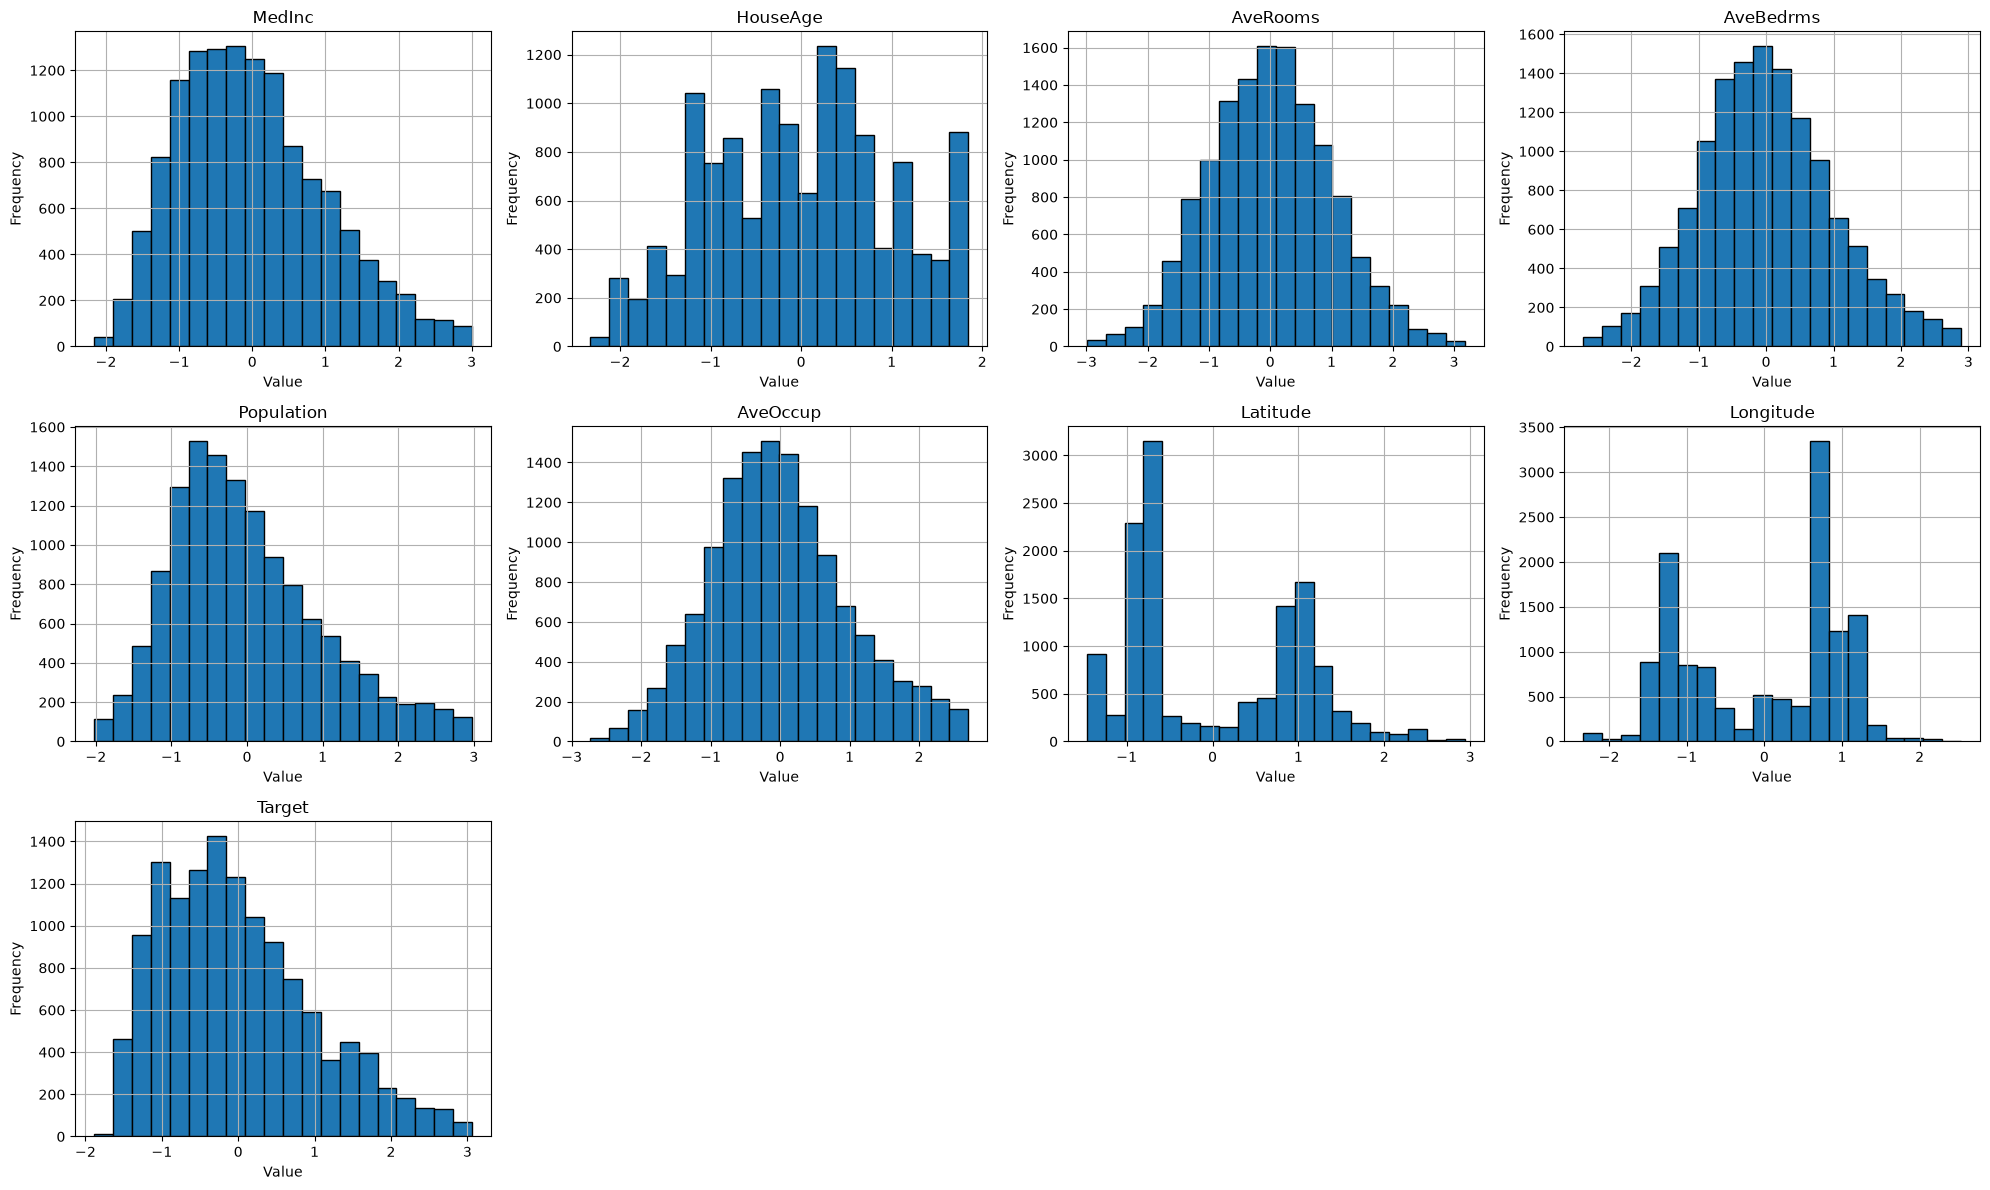

In [30]:
# Menghitung jumlah variabel
num_vars = df_lencoder.shape[1]

# Menentukan jumlah baris dan kolom untuk grid subplot
n_cols = 4  # Jumlah kolom yang diinginkan
n_rows = -(-num_vars // n_cols)  # Ceiling division untuk menentukan jumlah baris

# Membuat subplot
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 4))

# Flatten axes array untuk memudahkan iterasi jika diperlukan
axes = axes.flatten()

# Plot setiap variabel
for i, column in enumerate(df_lencoder.columns):
    df_lencoder[column].hist(ax=axes[i], bins=20, edgecolor='black')
    axes[i].set_title(column)
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')

# Menghapus subplot yang tidak terpakai (jika ada)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# Menyesuaikan layout agar lebih rapi
plt.tight_layout()
plt.show()

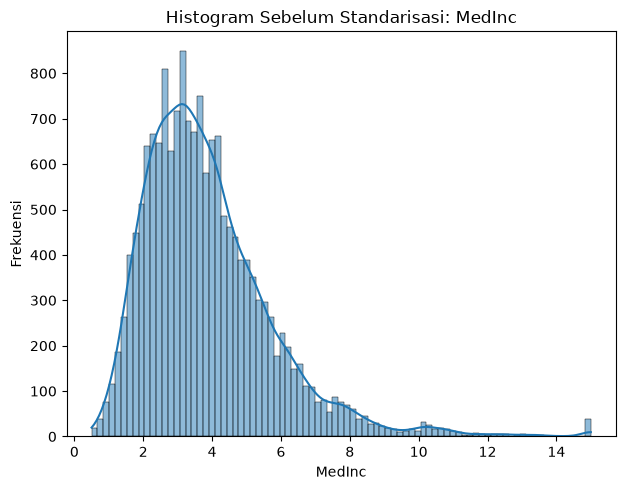

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

# Pastikan nama dataframe-nya sesuai (misal train)
# Mengambil kolom numerik secara otomatis
numeric_features = train.select_dtypes(include=['number']).columns

# Menampilkan histogram untuk kolom pertama (indeks 0) yang aman
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)

# Cek apakah kolomnya ada minimal 1
if len(numeric_features) > 0:
    sns.histplot(train[numeric_features[0]], kde=True)
    plt.title(f"Histogram Sebelum Standarisasi: {numeric_features[0]}")
    plt.xlabel(numeric_features[0])
    plt.ylabel("Frekuensi")
else:
    print("Tidak ada kolom numerik yang ditemukan.")

plt.tight_layout()
plt.show()

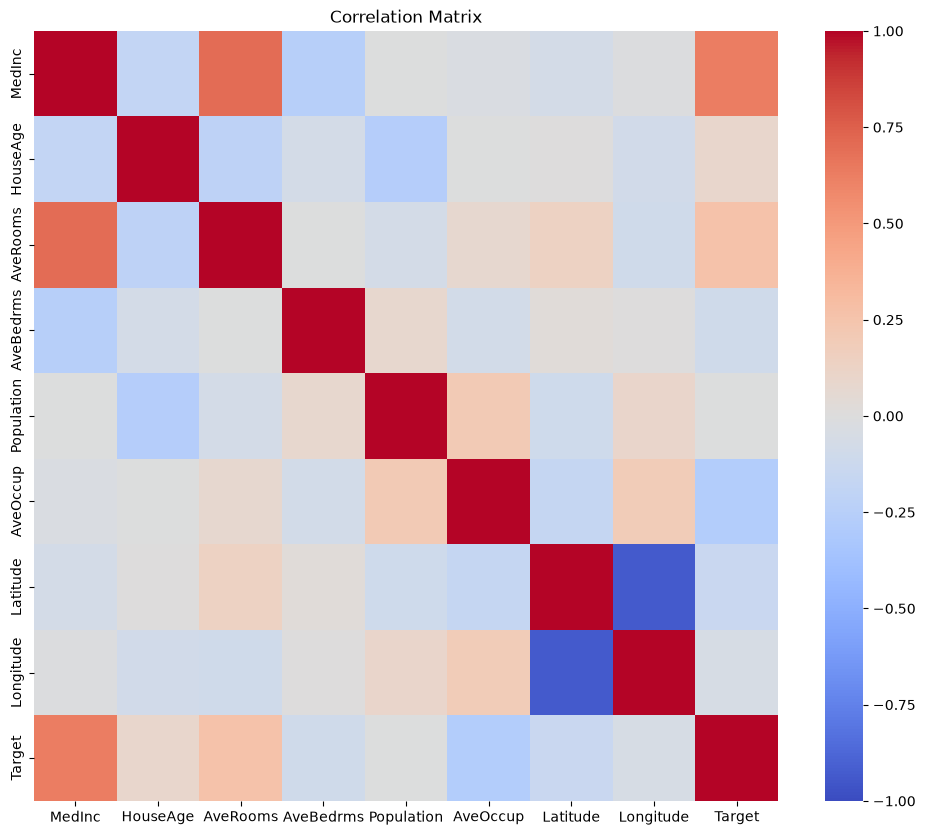

In [32]:
# Visualisasi korelasi antar variabel numerik
plt.figure(figsize=(12, 10))
correlation_matrix = df_lencoder.corr()

sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix')
plt.show()

In [33]:
from sklearn.datasets import fetch_california_housing
import pandas as pd

california = fetch_california_housing(as_frame=True)
df_lencoder = california.frame

Latihan: Data Splitting

In [34]:
import sklearn

In [35]:
# Memisahkan fitur (X) dan target (y)
X = df_lencoder.drop(columns=['MedHouseVal'])  
y = df_lencoder['MedHouseVal']

In [36]:
from sklearn.model_selection import train_test_split

# membagi dataset menjadi training dan testing 
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

In [37]:
# menghitung panjang/jumlah data 
print("Jumlah data: ", len(X))

# menghitung panjang/jumlah data pada x_train
print("Jumlah data latih: ", len(x_train))

# menghitung panjang/jumlah data pada x_test
print("Jumlah data test: ", len(x_test))

Jumlah data:  20640
Jumlah data latih:  16512
Jumlah data test:  4128


Pembangunan Model (Modelling)

Melatih Model (Training)

In [38]:
# Melatih model 1 dengan algoritma Least Angle Regression
from sklearn import linear_model
lars = linear_model.Lars(n_nonzero_coefs=1).fit(x_train, y_train)

# Melatih model 2 dengan algoritma Linear Regression
from sklearn.linear_model import LinearRegression
LR = LinearRegression().fit(x_train, y_train)

# Melatih model 3 dengan algoritma Gradient Boosting Regressor
from sklearn.ensemble import GradientBoostingRegressor
GBR = GradientBoostingRegressor(random_state=184)
GBR.fit(x_train, y_train)

,loss,'squared_error'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


Evaluasi Model

In [39]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Evaluasi pada model LARS
pred_lars = lars.predict(x_test)
mae_lars = mean_absolute_error(y_test, pred_lars)
mse_lars = mean_squared_error(y_test, pred_lars)
r2_lars = r2_score(y_test, pred_lars)

# Membuat dictionary untuk menyimpan hasil evaluasi
data = {
    'MAE': [mae_lars],
    'MSE': [mse_lars],
    'R2': [r2_lars]
}

# Konversi dictionary menjadi DataFrame
df_results = pd.DataFrame(data, index=['Lars'])
df_results

,MAE,MSE,R2
Lars,0.908828,1.312639,-0.000723


In [40]:
# Evaluasi pada model Linear Regression
pred_LR = LR.predict(x_test)
mae_LR = mean_absolute_error(y_test, pred_LR)
mse_LR = mean_squared_error(y_test, pred_LR)
r2_LR = r2_score(y_test, pred_LR)

# Menambahkan hasil evaluasi LR ke DataFrame
df_results.loc['Linear Regression'] = [mae_LR, mse_LR, r2_LR]
df_results

,MAE,MSE,R2
Lars,0.908828,1.312639,-0.000723
Linear Regression,0.532869,0.529140,0.596597


In [41]:
# Evaluasi pada model Gradient Boosting Regressor
pred_GBR = GBR.predict(x_test)
mae_GBR = mean_absolute_error(y_test, pred_GBR)
mse_GBR = mean_squared_error(y_test, pred_GBR)
r2_GBR = r2_score(y_test, pred_GBR)

# Menambahkan hasil evaluasi GBR ke DataFrame
df_results.loc['GradientBoostingRegressor'] = [mae_GBR, mse_GBR, r2_GBR]
df_results

,MAE,MSE,R2
Lars,0.908828,1.312639,-0.000723
Linear Regression,0.532869,0.529140,0.596597
GradientBoostingRegressor,0.369797,0.289845,0.779029


Menyimpan Model

Joblib

In [42]:
import joblib

# Menyimpan model ke dalam file
joblib.dump(GBR, 'gbr_model.joblib')

print("Model GBR berhasil disimpan ke file gbr_model.joblib!")

Model GBR berhasil disimpan ke file gbr_model.joblib!


Pickle

In [43]:
import pickle

# Menyimpan model ke dalam file
with open('gbr_model.pkl', 'wb') as file:
    pickle.dump(GBR, file)

print("Model GBR berhasil disimpan ke file gbr_model.pkl!")

Model GBR berhasil disimpan ke file gbr_model.pkl!


In [44]:
import pandas as pd

# Membaca file dataset (ganti nama filenya jika berbeda, misal train.csv atau test.csv)
df = pd.read_csv('train.csv')

# Menampilkan jumlah baris dan kolom
print(f"Jumlah baris: {df.shape[0]}")
print(f"Jumlah kolom: {df.shape[1]}")

# Kalau mau lihat ringkasan lengkapnya
print(df.info())

Jumlah baris: 16512
Jumlah kolom: 9
<class 'pandas.DataFrame'>
RangeIndex: 16512 entries, 0 to 16511
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      16512 non-null  float64
 1   HouseAge    16512 non-null  float64
 2   AveRooms    16512 non-null  float64
 3   AveBedrms   16512 non-null  float64
 4   Population  16512 non-null  float64
 5   AveOccup    16512 non-null  float64
 6   Latitude    16512 non-null  float64
 7   Longitude   16512 non-null  float64
 8   Target      16512 non-null  float64
dtypes: float64(9)
memory usage: 1.1 MB
None


Deployment dan Monitoring

In [45]:
import joblib
import pickle

# Memuat model dari file joblib
joblib_model = joblib.load('gbr_model.joblib')

# Memuat model dari file pickle
with open('gbr_model.pkl', 'rb') as file:
    pickle_model = pickle.load(file)

In [47]:
import requests

# Kirim data dengan tepat 8 fitur saja sesuai ekspektasi model
payload = {
    "data": [
        [1.5, 2.0, 3.1, 4.2, 5.0, 6.1, 7.2, 8.0], # Baris data pertama
        [2.0, 2.5, 3.0, 4.0, 5.1, 6.0, 7.0, 8.1]  # Baris data kedua
    ]
}

response = requests.post("http://127.0.0.1:8080/predict", json=payload)
print("Status:", response.status_code)
print("Hasil Prediksi:", response.json())

Status: 200
Hasil Prediksi: {'prediction': [0.5791391292980341, 0.5989076250817597]}
